# 1. 描述性统计

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/bank-additional-full.csv', sep=';')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

marital：婚姻情况

default：有无违约记录

balance：余额

housing：有无住房贷款

loan：有无个人贷款

contact：联系方式

month：最后联系月份

day：最后联系的日期

duration：最后一次通话时长

compaign：宣传活动中的联系次数

pdays：上次营销活动联系之后的天数

previous：上次营销活动之前的联系次数

poutcome：上一次营销活动的结果

'emp.var.rate', 'cons.price.idx','cons.conf.idx', 'euribor3m', 'nr.employed'为宏观经济指标，具体来说

Emp.var.rate：就业变化率——季度指标（数值型数据）

Cons.price.idx：消费者价格指数——月度数据（数值型）

Cons.conf.idx：消费者信心指数——月度指标（数值形式）

Euribor3m：欧元区 3 个月期利率——每日数值指标

就业人数：员工数量——季度指标（数值型数据）

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
df.isnull().sum().sum(), df.duplicated().sum()

(np.int64(0), np.int64(12))

没有缺失值和重复值

In [5]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


pdays中999表示该客户此前未被联系过，可以考虑将此前联系过的客户和未联系过的客户构造一个新特征。最后的几个宏观经济指标不清楚具体计算公式，在后续不进行特征工程，直接放进建模

从数据分布来看，duration，previous与campaign的中位数和均值相差较大，存在偏态分布，后续可考虑对数变换。duration的单位是秒，可以考虑转化成小时，减小影响。

In [6]:
df.describe(include='str')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


可以看出大部分变量为分类变量，可以进行独热编码，对二分类的可以转化为0，1

In [7]:
df['education'].value_counts(), df['marital'].value_counts(), df['poutcome'].value_counts()

(education
 university.degree      12168
 high.school             9515
 basic.9y                6045
 professional.course     5243
 basic.4y                4176
 basic.6y                2292
 unknown                 1731
 illiterate                18
 Name: count, dtype: int64,
 marital
 married     24928
 single      11568
 divorced     4612
 unknown        80
 Name: count, dtype: int64,
 poutcome
 nonexistent    35563
 failure         4252
 success         1373
 Name: count, dtype: int64)

In [8]:
df['default'].value_counts(), df['housing'].value_counts(), df['loan'].value_counts()

(default
 no         32588
 unknown     8597
 yes            3
 Name: count, dtype: int64,
 housing
 yes        21576
 no         18622
 unknown      990
 Name: count, dtype: int64,
 loan
 no         33950
 yes         6248
 unknown      990
 Name: count, dtype: int64)

In [9]:
df['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

可以看出目标变量存在严重的不平衡，后续建模时需要注意，并且主要关注PR和F1score来评估分类效果

# 2. EDA

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei'] 
plt.rcParams['axes.unicode_minus'] = False

In [11]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [12]:
df['y'] = df['y'].replace({'yes': 1, 'no': 0}).astype(int)
df_number = df.select_dtypes(include='number').columns
df_str = df.select_dtypes(include='str').columns

df[df_number].corr(method='pearson')

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,-0.000866,0.004594,-0.034369,0.024365,-0.000371,0.000857,0.129372,0.010767,-0.017725,0.030399
duration,-0.000866,1.000000,-0.071699,-0.047577,0.020640,-0.027968,0.005312,-0.008173,-0.032897,-0.044703,0.405274
campaign,0.004594,-0.071699,1.000000,0.052584,-0.079141,0.150754,0.127836,-0.013733,0.135133,0.144095,-0.066357
pdays,-0.034369,-0.047577,0.052584,1.000000,-0.587514,0.271004,0.078889,-0.091342,0.296899,0.372605,-0.324914
previous,0.024365,0.020640,-0.079141,-0.587514,1.000000,-0.420489,-0.203130,-0.050936,-0.454494,-0.501333,0.230181
emp.var.rate,-0.000371,-0.027968,0.150754,0.271004,-0.420489,1.000000,0.775334,0.196041,0.972245,0.906970,-0.298334
cons.price.idx,0.000857,0.005312,0.127836,0.078889,-0.203130,0.775334,1.000000,0.058986,0.688230,0.522034,-0.136211
cons.conf.idx,0.129372,-0.008173,-0.013733,-0.091342,-0.050936,0.196041,0.058986,1.000000,0.277686,0.100513,0.054878
euribor3m,0.010767,-0.032897,0.135133,0.296899,-0.454494,0.972245,0.688230,0.277686,1.000000,0.945154,-0.307771
nr.employed,-0.017725,-0.044703,0.144095,0.372605,-0.501333,0.906970,0.522034,0.100513,0.945154,1.000000,-0.354678


## 2.1 个人基本情况与目标变量的相关性
age, job, marital, education

In [13]:
df_1 = df[['age', 'job', 'marital', 'education', 'y']]
df_1['subscribed'] = (df_1['y'] == 1).astype(int)

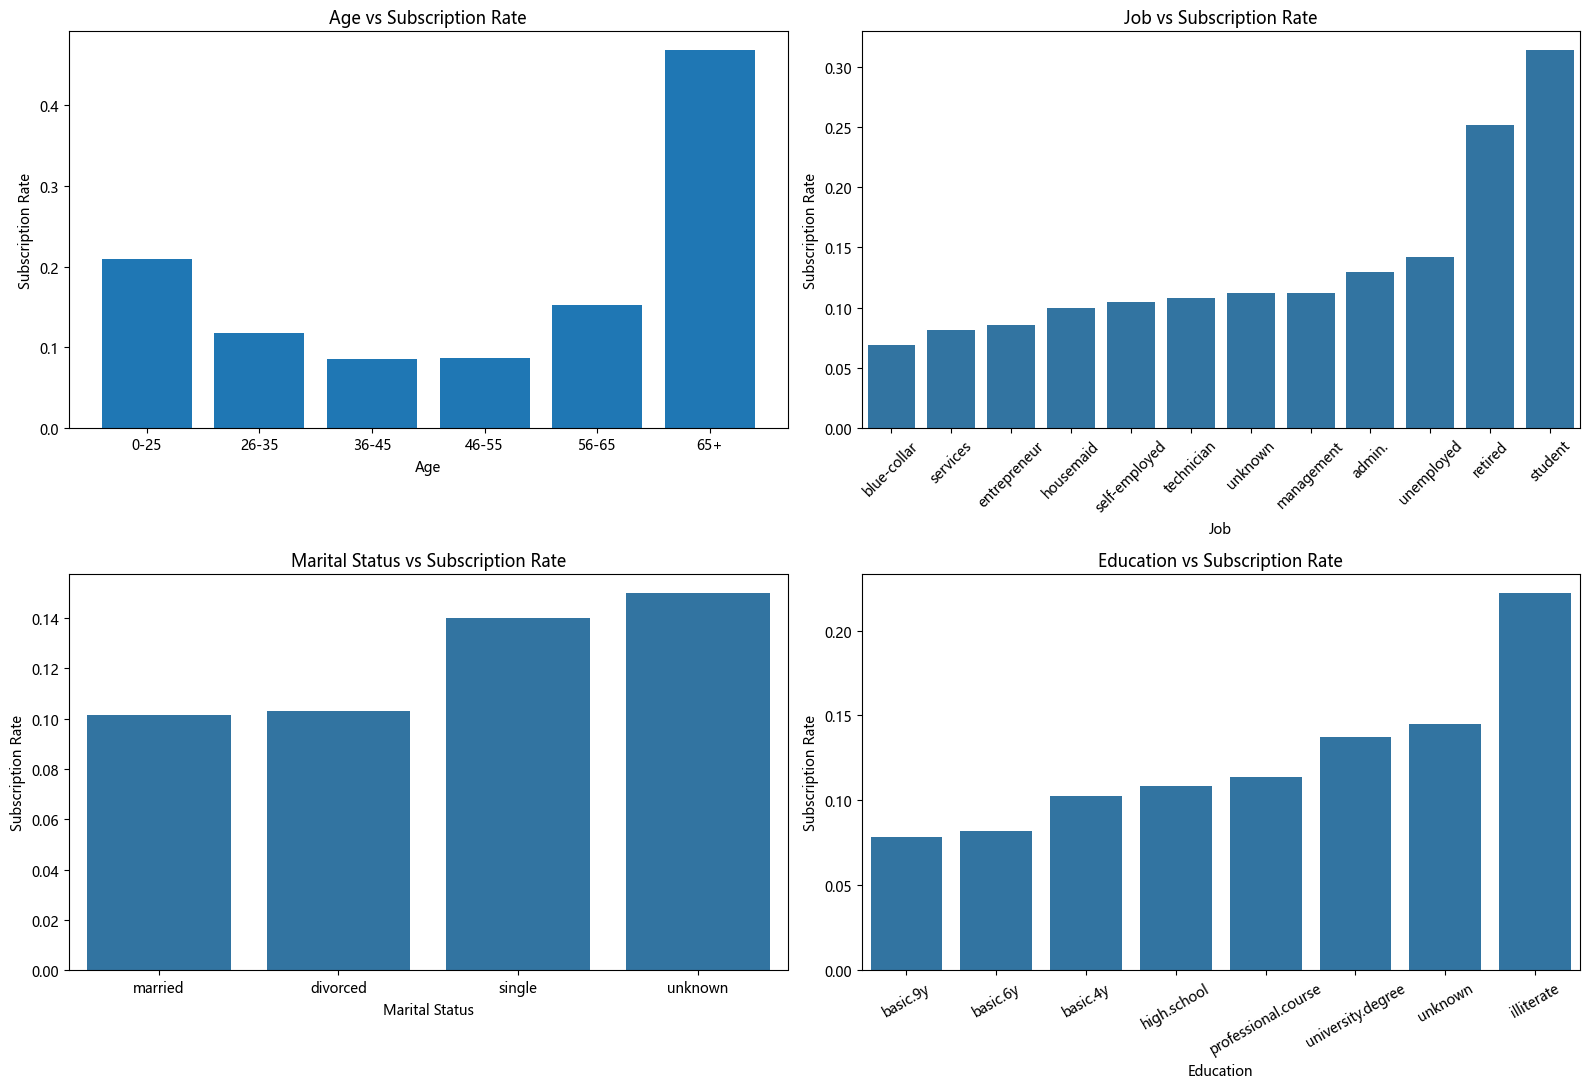

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. 年龄与订阅率，年龄分组
df_1['age_group'] = pd.cut(df_1['age'], bins=[0, 25, 35, 45, 55, 65, 100], labels=['0-25', '26-35', '36-45', '46-55', '56-65', '65+'])
age_rate = df_1.groupby('age_group')['subscribed'].mean()
axes[0, 0].bar(age_rate.index, age_rate.values)
axes[0, 0].set_title('Age vs Subscription Rate')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Subscription Rate')

# 2. 职业与订阅率
job_rate = df_1.groupby('job')['subscribed'].mean().sort_values()
sns.barplot(x=job_rate.index, y=job_rate.values, ax=axes[0, 1])
axes[0, 1].set_title('Job vs Subscription Rate')
axes[0, 1].set_xlabel('Job')
axes[0, 1].set_ylabel('Subscription Rate')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. 婚姻状况与订阅率
marital_rate = df_1.groupby('marital')['subscribed'].mean().sort_values()
sns.barplot(x=marital_rate.index, y=marital_rate.values, ax=axes[1, 0])
axes[1, 0].set_title('Marital Status vs Subscription Rate')
axes[1, 0].set_xlabel('Marital Status')
axes[1, 0].set_ylabel('Subscription Rate')

# 4. 教育程度与订阅率
education_rate = df_1.groupby('education')['subscribed'].mean().sort_values()
sns.barplot(x=education_rate.index, y=education_rate.values, ax=axes[1, 1])
axes[1, 1].set_title('Education vs Subscription Rate')
axes[1, 1].set_xlabel('Education')
axes[1, 1].set_ylabel('Subscription Rate')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

结合年龄分组和job可以看出，学生（25岁以下）以及退休（65岁+）的订阅率相比更高，其他的差异不大；而在婚姻状况中，单身包含离异的订阅率更高；在受教育情况中，受过高等教育的订阅率更高

## 2.2 个人经济情况与目标变量的相关性
default, housing, loan

In [15]:
df_2 = df[['default', 'housing', 'loan']]
df_2['subscribed'] = (df['y'] == 1).astype(int)

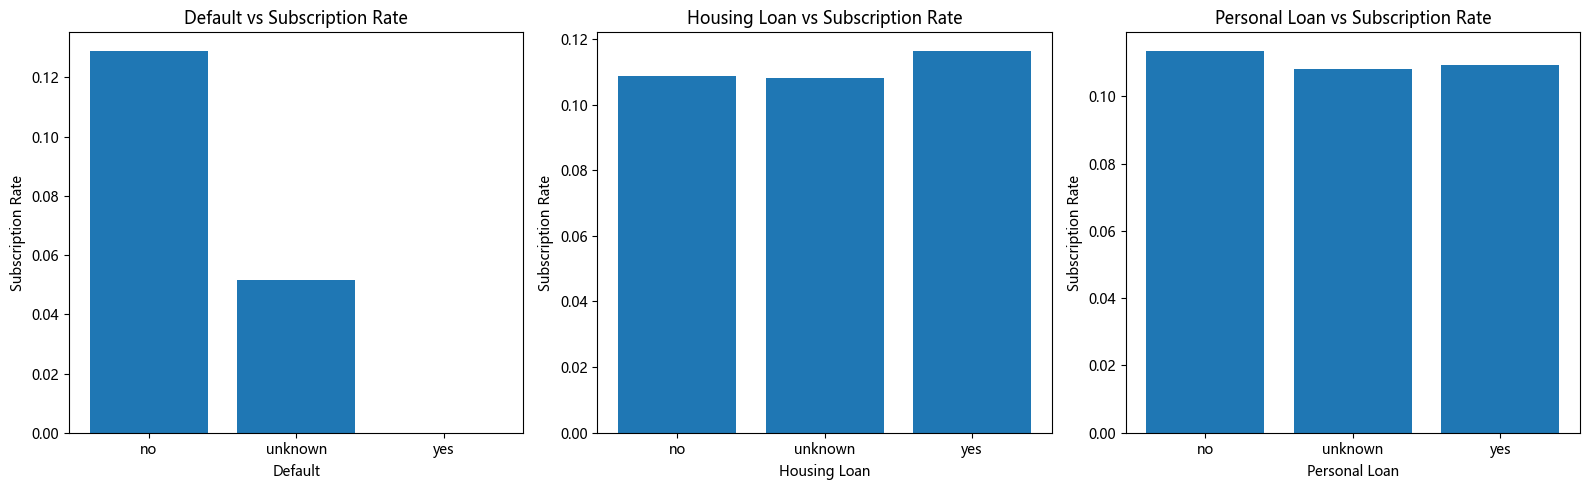

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 违约记录与订阅率
default_rate = df_2.groupby('default')['subscribed'].mean()
axes[0].bar(default_rate.index, default_rate.values)
axes[0].set_title('Default vs Subscription Rate')
axes[0].set_xlabel('Default')
axes[0].set_ylabel('Subscription Rate')

# 住房贷款与订阅率
housing_rate = df_2.groupby('housing')['subscribed'].mean()
axes[1].bar(housing_rate.index, housing_rate.values)
axes[1].set_title('Housing Loan vs Subscription Rate')
axes[1].set_xlabel('Housing Loan')
axes[1].set_ylabel('Subscription Rate')

# 个人贷款与订阅率
loan_rate = df_2.groupby('loan')['subscribed'].mean()
axes[2].bar(loan_rate.index, loan_rate.values)
axes[2].set_title('Personal Loan vs Subscription Rate')
axes[2].set_xlabel('Personal Loan')
axes[2].set_ylabel('Subscription Rate')


plt.tight_layout()
plt.show()

从上面三个图可以看出，经济情况与订阅率的关系看不出来显著的区别，注意default中有违约记录(yes)的数据只有三个

## 2.3 营销性活动与目标变量的相关性
campaign, pdays, previous, contact, poutcome，duration

month, day_of_week

In [17]:
df_3 = df[['campaign', 'pdays', 'previous', 'poutcome', 'contact', 'month', 'day_of_week', 'duration']]
df_3['subscribed'] = (df['y'] == 1).astype(int)
df_3.head()

,campaign,pdays,previous,poutcome,contact,month,day_of_week,duration,subscribed
0,1,999,0,nonexistent,telephone,may,mon,261,0
1,1,999,0,nonexistent,telephone,may,mon,149,0
2,1,999,0,nonexistent,telephone,may,mon,226,0
3,1,999,0,nonexistent,telephone,may,mon,151,0
4,1,999,0,nonexistent,telephone,may,mon,307,0


In [18]:
df_3['pdays'].value_counts()

pdays
999    39673
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
13        36
11        28
1         26
15        24
14        20
8         18
0         15
16        11
17         8
18         7
22         3
19         3
21         2
25         1
26         1
27         1
20         1
Name: count, dtype: int64

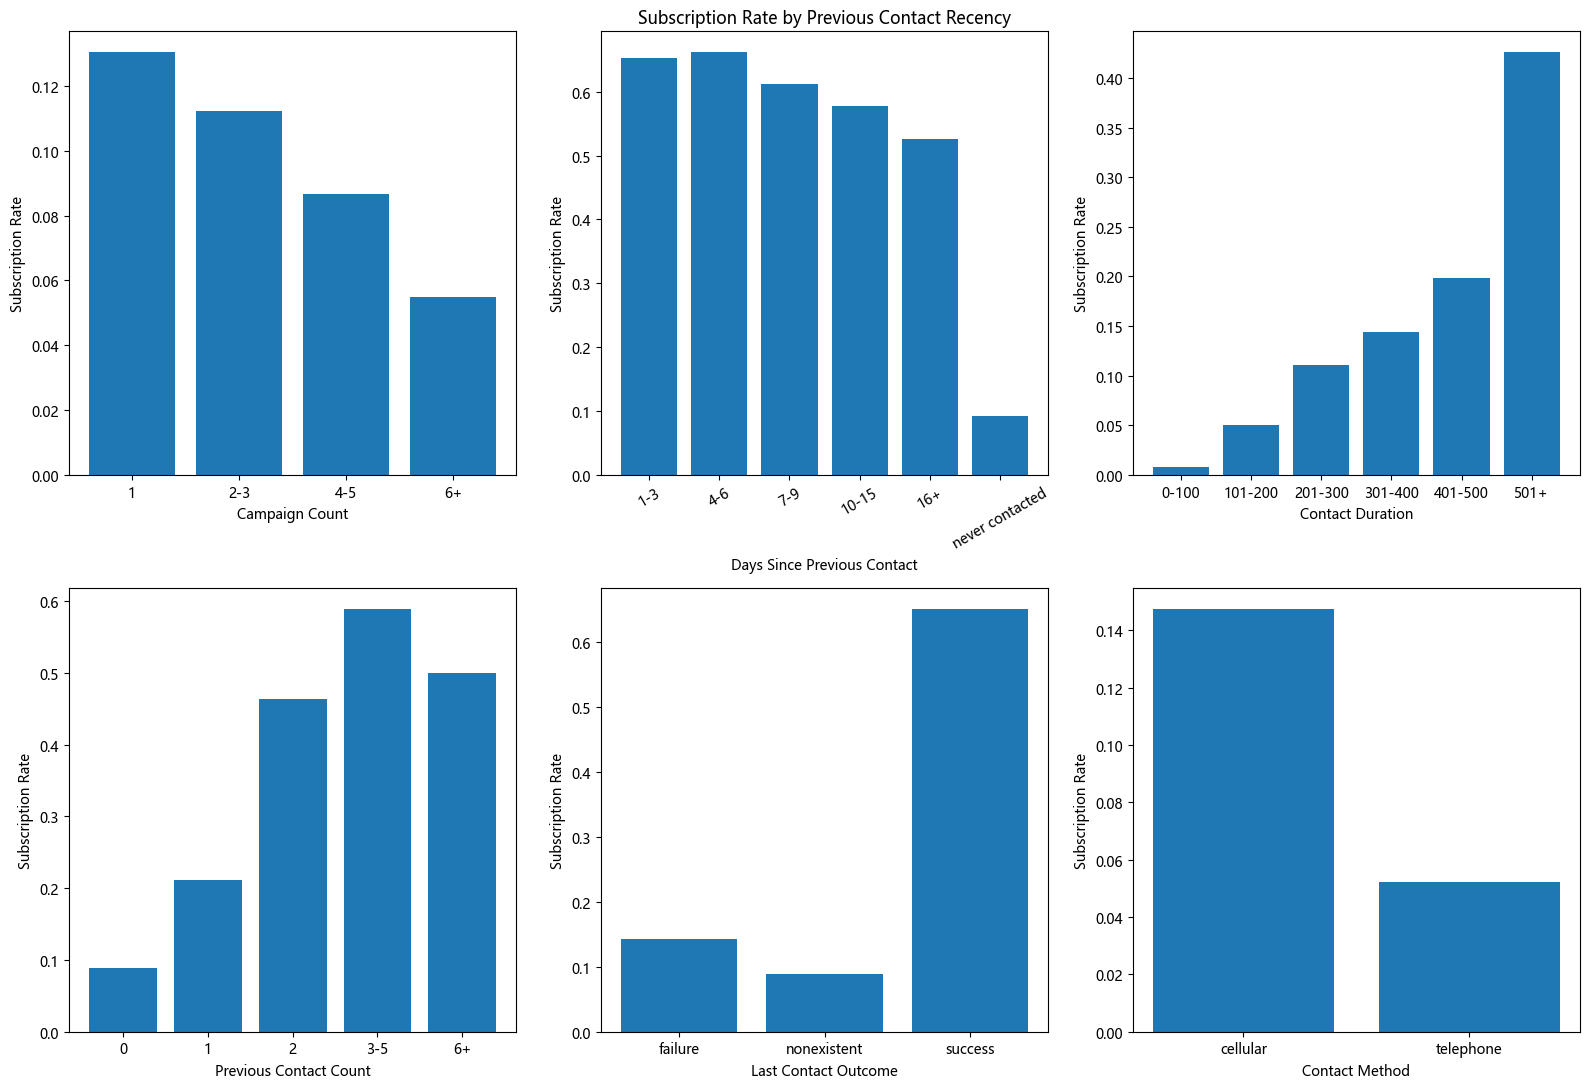

In [19]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 11))
gs = gridspec.GridSpec(2, 3, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])       
ax2 = fig.add_subplot(gs[0, 1])     
ax3 = fig.add_subplot(gs[1, 0])       
ax4 = fig.add_subplot(gs[1, 1])       
ax5 = fig.add_subplot(gs[1, 2]) 
ax6 = fig.add_subplot(gs[0, 2])     
axes = [ax1, ax2, ax3, ax4, ax5, ax6]      

# 在本次营销活动中联系次数与订阅率
df_3['campaign_group'] = pd.cut(df_3['campaign'], bins=[0, 1, 3, 5, np.inf], labels=['1', '2-3', '4-5', '6+'])
campaign_rate = df_3.groupby('campaign_group')['subscribed'].mean()
ax1.bar(campaign_rate.index, campaign_rate.values)
ax1.set_xlabel('Campaign Count')
ax1.set_ylabel('Subscription Rate')

# 上一次联系后天数与订阅率，天数分组，注意999需单独分组
# 将 pdays 分为“从未联系”和“曾经联系”
df_3['pdays_group'] = pd.cut(df_3['pdays'].where(df_3['pdays'] != 999), bins=[-1, 3, 6, 9, 15, np.inf], labels=['1-3', '4-6', '7-9', '10-15', '16+'])
df_3['pdays_group'] = df_3['pdays_group'].cat.add_categories(['never contacted'])
df_3.loc[df_3['pdays'] == 999, 'pdays_group'] = 'never contacted'
pdays_rate = df_3.groupby('pdays_group', observed=False)['subscribed'].mean()

ax2.bar(pdays_rate.index.astype(str), pdays_rate.values)
ax2.set_xlabel('Days Since Previous Contact')
ax2.set_ylabel('Subscription Rate')
ax2.set_title('Subscription Rate by Previous Contact Recency')
ax2.tick_params(axis='x', rotation=30)

# 联系方式与订阅率
contact_rate = df_3.groupby('contact')['subscribed'].mean()
ax5.bar(contact_rate.index, contact_rate.values)
ax5.set_xlabel('Contact Method')
ax5.set_ylabel('Subscription Rate')

# 之前联系次数与订阅率，次数分组
df_3['previous_group'] = pd.cut(df_3['previous'], bins=[-2, 0, 1, 2, 5, np.inf], labels=['0', '1', '2', '3-5', '6+'])
previous_rate = df_3.groupby('previous_group')['subscribed'].mean()
ax3.bar(previous_rate.index, previous_rate.values)
ax3.set_xlabel('Previous Contact Count')
ax3.set_ylabel('Subscription Rate')

# 上一次联系结果与订阅率
poutcome_rate = df_3.groupby('poutcome')['subscribed'].mean()
ax4.bar(poutcome_rate.index, poutcome_rate.values)
ax4.set_xlabel('Last Contact Outcome')
ax4.set_ylabel('Subscription Rate')

# 联系时间与订阅率，时长分组
df_3['duration_group'] = pd.cut(df_3['duration'], bins=[0, 100, 200, 300, 400, 500, np.inf], labels=['0-100', '101-200', '201-300', '301-400', '401-500', '501+'])
duration_rate = df_3.groupby('duration_group')['subscribed'].mean()
ax6.bar(duration_rate.index, duration_rate.values)
ax6.set_xlabel('Contact Duration')
ax6.set_ylabel('Subscription Rate')

plt.tight_layout()
plt.show()

可以看出来，营销活动的成功与否以及联系次数对订阅率的影响是较为明显的，注意根据数据集的提示duration应在后续建模时去掉

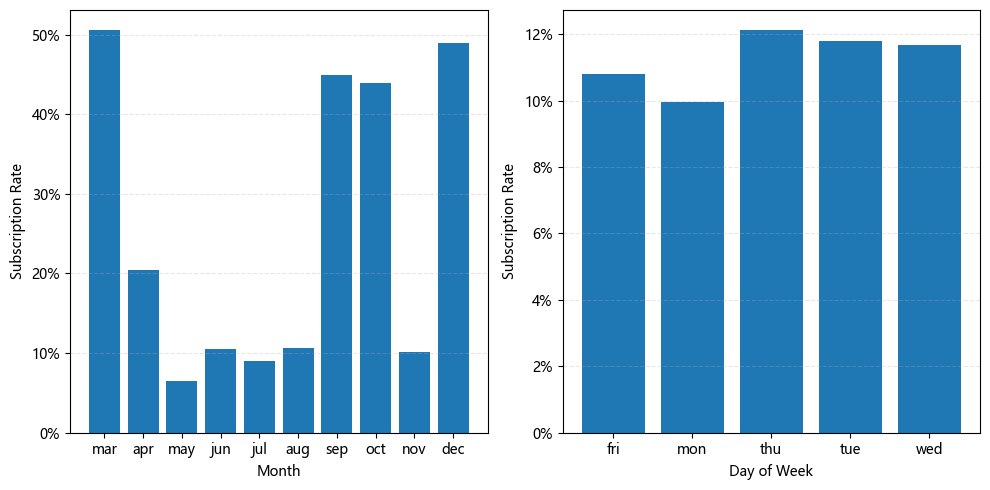

In [20]:
# 上一次联系月份与日期和订阅率
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 1. 上一次联系月份与订阅率
month_rate = df_3.groupby('month')['subscribed'].mean().reindex(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])
axes[0].bar(month_rate.index, month_rate.values)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Subscription Rate')

# 2. 上一次联系日期与订阅率
date_rate = df_3.groupby('day_of_week')['subscribed'].mean()
axes[1].bar(date_rate.index, date_rate.values)
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Subscription Rate')

for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

可以看到，不同月份订阅率有一定差异，但无明显规律，而不同日期的订阅率变化不大，对这两者后续考虑进行独热编码

## 2.4 宏观经济指标

In [21]:
df_4 = df[['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']]
df_4.describe()

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,0.081886,93.575664,-40.502600,3.621291,5167.035911,0.112654
std,1.570960,0.578840,4.628198,1.734447,72.251528,0.316173
min,-3.400000,92.201000,-50.800000,0.634000,4963.600000,0.000000
25%,-1.800000,93.075000,-42.700000,1.344000,5099.100000,0.000000
50%,1.100000,93.749000,-41.800000,4.857000,5191.000000,0.000000
75%,1.400000,93.994000,-36.400000,4.961000,5228.100000,0.000000
max,1.400000,94.767000,-26.900000,5.045000,5228.100000,1.000000


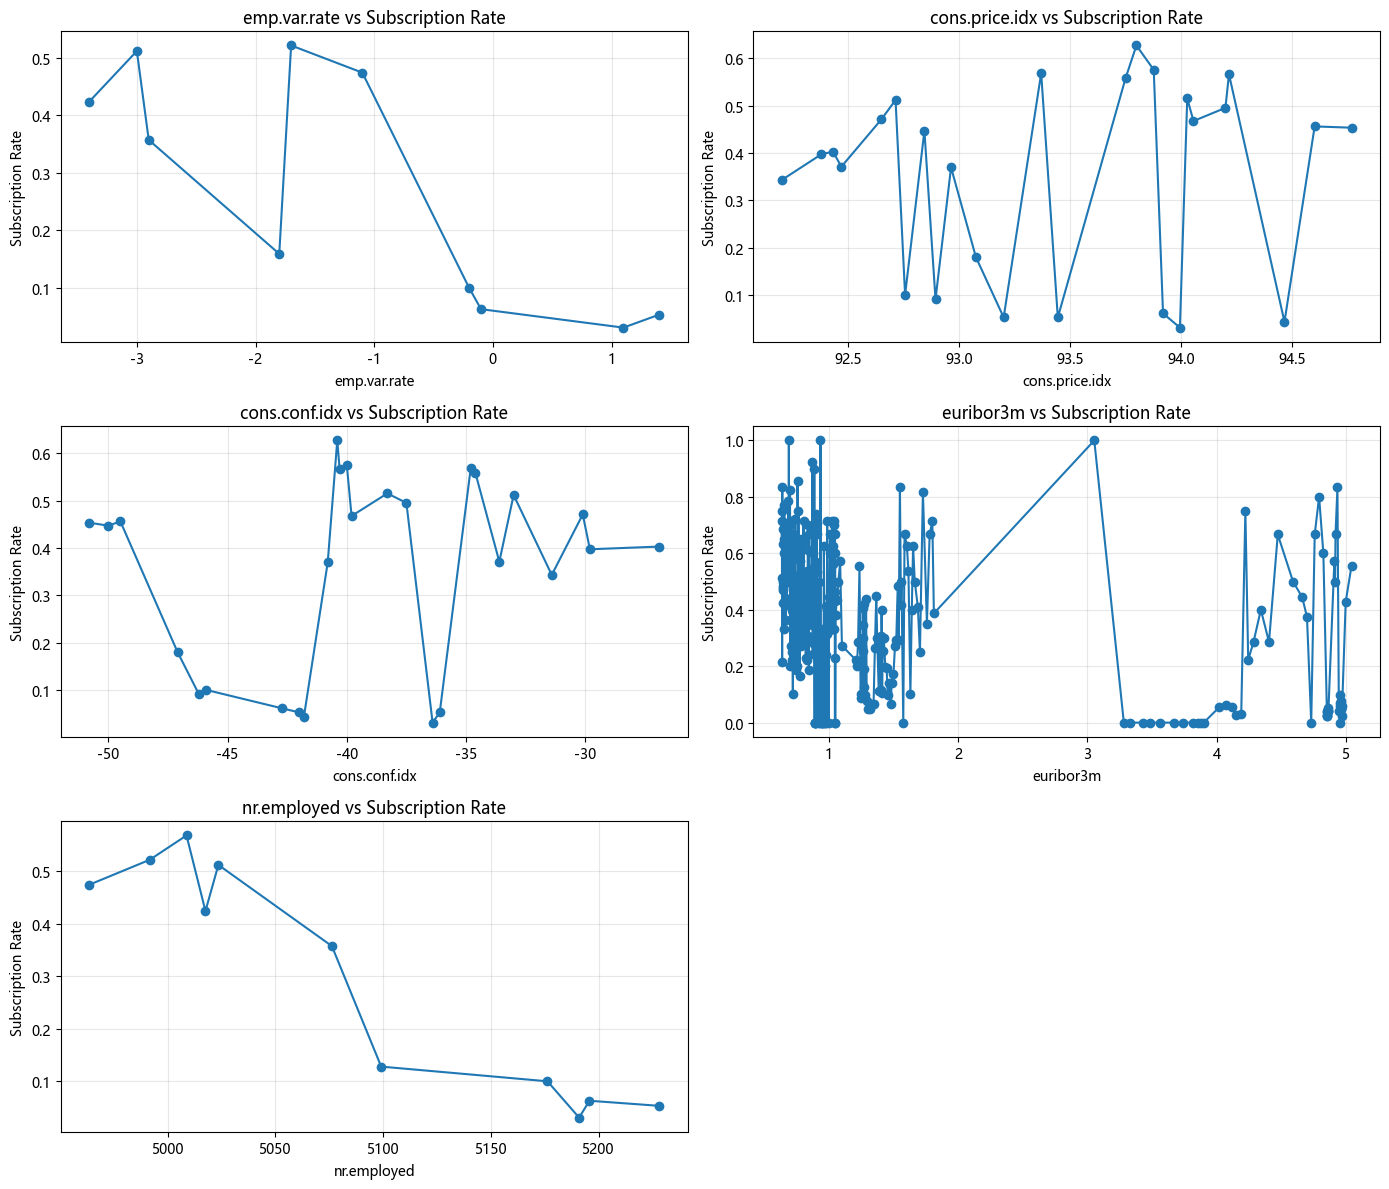

In [22]:
cols = ['emp.var.rate', 'cons.price.idx',
        'cons.conf.idx', 'euribor3m', 'nr.employed']

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(cols):
    rate = df_4.groupby(col)['y'].mean().sort_index()

    axes[i].plot(rate.index, rate.values, marker='o')
    axes[i].set_title(f'{col} vs Subscription Rate')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Subscription Rate')
    axes[i].grid(alpha=0.3)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

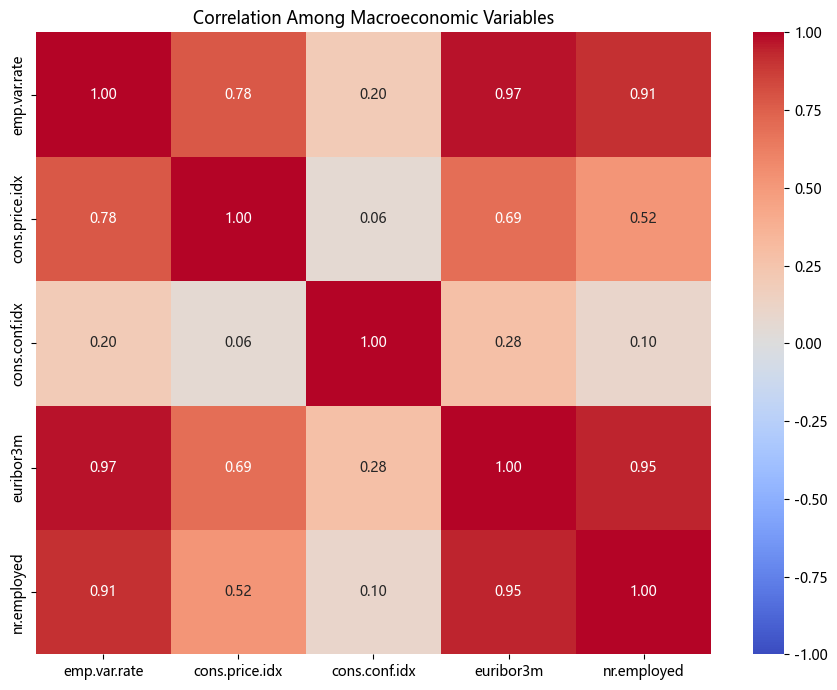

In [23]:
corr = df_4[cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Among Macroeconomic Variables')
plt.tight_layout()
plt.show()

# 3. 总结

1. 对 campaign、previous 尝试对数变换。
2. 对于pdays，区分客户以前是否被联系过
3. 对于年龄可以考虑分箱
4. 其他正常进行独热编码或者二分类